In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/CS8803-VLM

/content/drive/.shortcut-targets-by-id/1Ruq2IakN1ydR63tm8_LALd9dJtrbmPfp/CS8803-VLM


In [ ]:
import json, random
rows = [json.loads(l) for l in open("data/gqa_cot_train.jsonl")]

# for initial experiments just sample 500 images
# for now only use images where the area of the bounding box is not too big or too small

def area_frac(r):
    x1, y1, x2, y2 = r["bboxs"][0]
    return (x2 - x1) * (y2 - y1) / (r["width"] * r["height"])

good = [r for r in rows
        if len(r["bboxs"]) == 1
        and 0.05 <= area_frac(r) <= 0.5
        and len(r["answer"].split()) <= 2]
random.seed(0)
subset = random.sample(good, 500)

In [ ]:
import os
import urllib.request
from tqdm import tqdm
from urllib.error import HTTPError


#stanford hosts using two links so this cell downloads the 500 image subset so we don't have to download the 20 GB dataset yet

image_filenames = []
failed_images = []
for example in subset:
  image_filenames.append(example["image"])

os.makedirs("data/image_subset", exist_ok=True)
success_count = 0
for filename in tqdm(image_filenames, desc="Downloading GQA Subsample Images"):
        target_path = os.path.join("data/image_subset", filename)

        # Skip download if file is already there
        if os.path.exists(target_path):
            success_count += 1
            continue

        # Stanford GQA raw image asset endpoint
        try:
            url = f"https://cs.stanford.edu/people/rak248/VG_100K/{filename}"
            urllib.request.urlretrieve(url, target_path)
            success_count += 1
        except HTTPError as e:
            if e.code == 404:
                # Fallback to folder 2 if it wasn't found in folder 1
                fallback_url = f"https://cs.stanford.edu/people/rak248/VG_100K_2/{filename}"
                try:
                    urllib.request.urlretrieve(fallback_url, target_path)
                    success_count += 1
                except Exception as fallback_err:
                    print(f"\n[404 Both] Failed to download {filename} from either folder: {fallback_err}")
                    failed_images.append(filename)
            else:
                print(f"\n[Error] HTTP Error {e.code} for {filename}: {e.reason}")
                failed_images.append(filename)
print(f"\nFinished! Successfully verified/downloaded {success_count}/{len(image_filenames)} images.")


Finished! Successfully verified/downloaded 500/500 images.


In [ ]:
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration
from pathlib import Path

import torch

# download the model

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen2.5-VL-7B-Instruct", torch_dtype=getattr(torch, "bfloat16"), device_map="auto"
)
model.eval()
processor = AutoProcessor.from_pretrained("Qwen/Qwen2.5-VL-7B-Instruct")

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/57.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

In [ ]:
# set up the instruction so the model only outputs the target entity
# add this instruction as part of the input and pass the image and question to the model

INSTRUCTION = (
    "Answer the question with only the key word or short phrase. "
    "Do not write a full sentence and do not use punctuation.\n\n"
    "Q: What is the man holding?\nA: umbrella\n\n"
    "Q: What color is the bus?\nA: red\n\n"
)

def make_inputs(processor, question, image=None):
    """Chat-formatted prompt ending right where the assistant's answer begins."""
    content = [{"type": "text", "text": INSTRUCTION + f"Q: {question}\nA:"}]
    if image is not None:
        content = [{"type": "image"}] + content
    messages = [{"role": "user", "content": content}]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    if image is not None:
        return processor(text=[prompt], images=[image], return_tensors="pt")
    return processor(text=[prompt], return_tensors="pt")

In [ ]:
# answer generation function

@torch.no_grad()
def generate_answer(model, processor, question, image=None, max_new_tokens=8):
    inputs = make_inputs(processor, question, image).to(model.device)
    out = model.generate(
        **inputs, max_new_tokens=max_new_tokens, do_sample=False,
        temperature=None, top_p=None, top_k=None,
    )
    new = out[0, inputs["input_ids"].shape[1]:]
    return processor.tokenizer.decode(new, skip_special_tokens=True).strip()

In [ ]:
# this function first creates the input by adding the image to the question and adding the instruction template
# then the answer is tacked on so the model each token of the answer to predict the next token in the answer (teacher forcing)
# keep track of the prompt length so you get the log probs for only the answer tokens
# the nth row in the logits holds the probs for the n+1th token so go up to the last token because last token predicts a nonexistent next token
# index each row of the logits with the target token so you get the probability of picking out the correct token
# sum the log probs to get the model's likelihood of getting the right answer
@torch.no_grad() #since we're not training so I don't run out of memory
def answer_logprob(model, processor, image, question, answer):
    inputs = make_inputs(processor, question, image)
    n_prompt = inputs["input_ids"].shape[1]

    # tokenize the answer on its own and append it (teacher forcing)
    ans_ids = processor.tokenizer(answer, add_special_tokens=False, return_tensors="pt")["input_ids"]
    inputs["input_ids"] = torch.cat([inputs["input_ids"], ans_ids], dim=1)
    # inputs["attention_mask"] = torch.ones_like(inputs["input_ids"])
    inputs = inputs.to(model.device)

    out = model(
      input_ids=inputs["input_ids"],
      pixel_values=inputs.get("pixel_values"),
      image_grid_thw=inputs.get("image_grid_thw"),
    )
    logits = out.logits[0]
    ids = inputs["input_ids"][0]
    logp = torch.log_softmax(logits[:-1].float(), -1).gather(1, ids[1:, None])[:, 0]
    ans_logp = logp[n_prompt - 1:]
    return ans_logp.sum().item(), ans_logp.mean().item()

In [ ]:
from PIL import Image
FILL = (124, 116, 104)            # use this same gray in every masked view

def mask_outside(img, box):
    out = Image.new("RGB", img.size, FILL)   # gray canvas, same size as the original
    out.paste(img.crop(box), box[:2])        # paste the boxed region back at its original position
    return out

def mask_evidence(img, box):
    out = img.copy()
    out.paste(FILL, box)                     # gray out only boxed region
    return out

def random_box_outside(img_size, box):
    W, H = img_size
    l, u, r, b = box
    w, h = r - l, b - u

    mx0, mx1 = max(0, l - w + 1), min(W - w, r - 1)  # x range overlapping box horizontally

    regions = [
        (0, l - w, 0, H - h),      # left, full height
        (r, W - w, 0, H - h),      # right, full height
        (mx0, mx1, 0, u - h),      # above, middle columns only
        (mx0, mx1, b, H - h),      # below, middle columns only
    ]
    regions = [g for g in regions if g[0] <= g[1] and g[2] <= g[3]]
    if not regions:
        raise RuntimeError("No non-overlapping placement exists.")

    areas = [(g[1] - g[0] + 1) * (g[3] - g[2] + 1) for g in regions]
    x0, x1, y0, y1 = random.choices(regions, weights=areas, k=1)[0]
    x, y = random.randint(x0, x1), random.randint(y0, y1)
    return (x, y, x + w, y + h)


def mask_irrelevant_region(img, box):
    try:
      rand_box = random_box_outside(img.size, box)
    except RuntimeError:
      return None, None
    return mask_evidence(img, rand_box), rand_box

In [ ]:
# compare question only vs full image and question on 500 image-question pairs
import json, numpy as np
from PIL import Image, UnidentifiedImageError

results = []
full_results, qonly_results, evidence_only_results  = [], [], []
for example in subset:
    try:
      img = Image.open(f"data/image_subset/{example['image']}").convert("RGB")
    except UnidentifiedImageError:
      continue
    gt = example["answer"].strip().lower()
    # this subset only has one bounding box per image so it's fine -- we can change this later
    box = tuple(example["bboxs"][0])
    evidence_only = mask_outside(img, box)
    _, full  = answer_logprob(model, processor, img,  example["question"], gt)   # [1] = the per-token mean
    _, qonly = answer_logprob(model, processor, None, example["question"], gt)
    _, box_only = answer_logprob(model, processor, evidence_only, example["question"], gt)
    full_results.append(full)
    qonly_results.append(qonly)
    evidence_only_results.append(box_only)
    print(f"{example['question'][:45]:45s} gt={gt:12s} full={full:6.2f} qonly={qonly:6.2f} evidence_only={box_only:6.2f}")

print("Mean NLL for Full Image Across 500 Examples: ", -np.mean(np.array(full_results)))
print("Mean NLL for Question Only Across 500 Examples: ", -np.mean(np.array(qonly_results)))
print("Mean NLL for Evidence Only Across 500 Examples: ", -np.mean(np.array(evidence_only_results)))

Who is wearing a sweater?                     gt=woman        full= -0.82 qonly= -0.61 evidence_only= -0.07
What is the towel on?                         gt=bench        full= -3.23 qonly= -3.67 evidence_only= -2.44
Which kind of animal is fluffy?               gt=cat          full= -0.00 qonly= -0.30 evidence_only= -0.00
What is the man wearing?                      gt=wetsuit      full= -0.02 qonly= -3.99 evidence_only= -0.17
Who is wearing a flip flop?                   gt=boy          full= -8.10 qonly= -5.01 evidence_only= -3.17
Where is that grass?                          gt=field        full= -0.73 qonly= -0.48 evidence_only= -0.57
What is on the table?                         gt=vases        full= -0.10 qonly= -5.84 evidence_only= -5.08
What is the binder on?                        gt=shelf        full= -1.51 qonly= -6.13 evidence_only= -0.17
What is that water in front of?               gt=trees        full= -1.26 qonly= -4.58 evidence_only= -1.00
What kind of watercraft are 

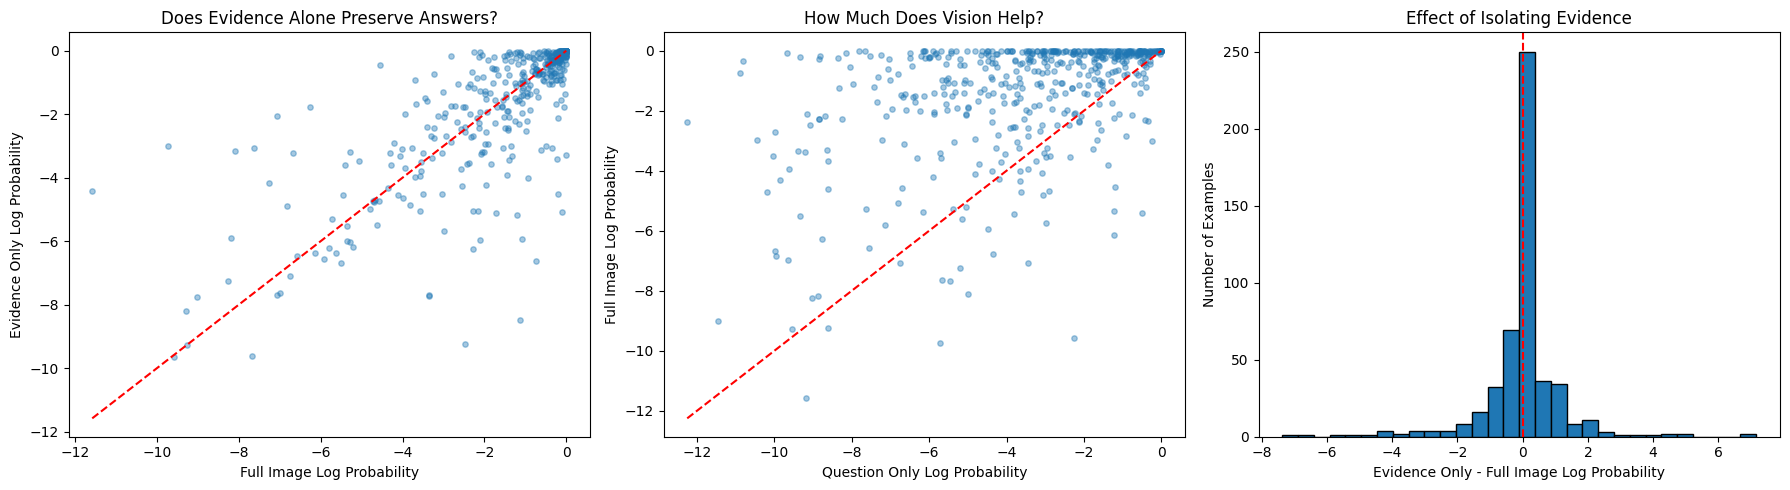

Examples: 499
Mean full-image NLL: 1.363
Mean evidence-only NLL: 1.394
Mean question-only NLL: 3.437
Evidence-only improves likelihood: 49.1%


In [ ]:
#visualization
import numpy as np
import matplotlib.pyplot as plt

full = np.array(full_results)
qonly = np.array(qonly_results)
evidence = np.array(evidence_only_results)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Full image vs evidence only
axes[0].scatter(full, evidence, alpha=0.4, s=15)
lo = min(full.min(), evidence.min())
hi = max(full.max(), evidence.max())
axes[0].plot([lo, hi], [lo, hi], 'r--')
axes[0].set_xlabel("Full Image Log Probability")
axes[0].set_ylabel("Evidence Only Log Probability")
axes[0].set_title("Does Evidence Alone Preserve Answers?")

# Plot 2: Full image vs question only
axes[1].scatter(qonly, full, alpha=0.4, s=15)
lo = min(qonly.min(), full.min())
hi = max(qonly.max(), full.max())
axes[1].plot([lo, hi], [lo, hi], 'r--')
axes[1].set_xlabel("Question Only Log Probability")
axes[1].set_ylabel("Full Image Log Probability")
axes[1].set_title("How Much Does Vision Help?")

# Plot 3: Distribution of evidence-only effects
difference = evidence - full

axes[2].hist(difference, bins=30, edgecolor="black")
axes[2].axvline(0, color="red", linestyle="--")
axes[2].set_xlabel("Evidence Only - Full Image Log Probability")
axes[2].set_ylabel("Number of Examples")
axes[2].set_title("Effect of Isolating Evidence")

plt.tight_layout()
plt.show()

print(f"Examples: {len(full)}")
print(f"Mean full-image NLL: {-full.mean():.3f}")
print(f"Mean evidence-only NLL: {-evidence.mean():.3f}")
print(f"Mean question-only NLL: {-qonly.mean():.3f}")
print(f"Evidence-only improves likelihood: {(difference > 0).mean():.1%}")


In [ ]:

import pandas as pd
from tqdm.auto import tqdm
from PIL import Image, UnidentifiedImageError

results = []
skipped = []

for example in tqdm(subset):
    try:
        img = Image.open(
            f"data/image_subset/{example['image']}"
        ).convert("RGB")
    except (UnidentifiedImageError, OSError):
        skipped.append(example["image"])
        continue

    box = tuple(example["bboxs"][0])
    masked_img = mask_evidence(img, box)
    gt = example["answer"].strip().lower()

    total_lp, mean_lp = answer_logprob(
        model, processor, masked_img,
        example["question"], gt
    )

    results.append({
        "image": example["image"],
        "question": example["question"],
        "answer": gt,
        "evidence_removed_logprob": mean_lp,
        "evidence_removed_logprob_sum": total_lp
    })

    # Same printing style as Aryan
    print(
        f"{example['question'][:45]:45s} "
        f"gt={gt:12s} "
        f"evidence_removed={mean_lp:6.2f}"
    )

df = pd.DataFrame(results)

print("\nSuccessfully evaluated:", len(df))
print("Skipped images:", skipped)
print("Mean evidence-removed NLL:",
      -df["evidence_removed_logprob"].mean())

os.makedirs("results", exist_ok=True)

df.to_csv("results/evidence_removed_results.csv", index=False)


  0%|          | 0/500 [00:00<?, ?it/s]

Who is wearing a sweater?                     gt=woman        evidence_removed= -0.28
What is the towel on?                         gt=bench        evidence_removed= -3.09
Which kind of animal is fluffy?               gt=cat          evidence_removed= -0.69
What is the man wearing?                      gt=wetsuit      evidence_removed= -0.43
Who is wearing a flip flop?                   gt=boy          evidence_removed= -7.31
Where is that grass?                          gt=field        evidence_removed= -1.50
What is on the table?                         gt=vases        evidence_removed= -0.12
What is the binder on?                        gt=shelf        evidence_removed= -7.97
What is that water in front of?               gt=trees        evidence_removed= -0.71
What kind of watercraft are the passengers on gt=canoe        evidence_removed= -1.30
Who is wearing the helmet?                    gt=jockey       evidence_removed= -2.22
What item of furniture is broken?             gt=chair

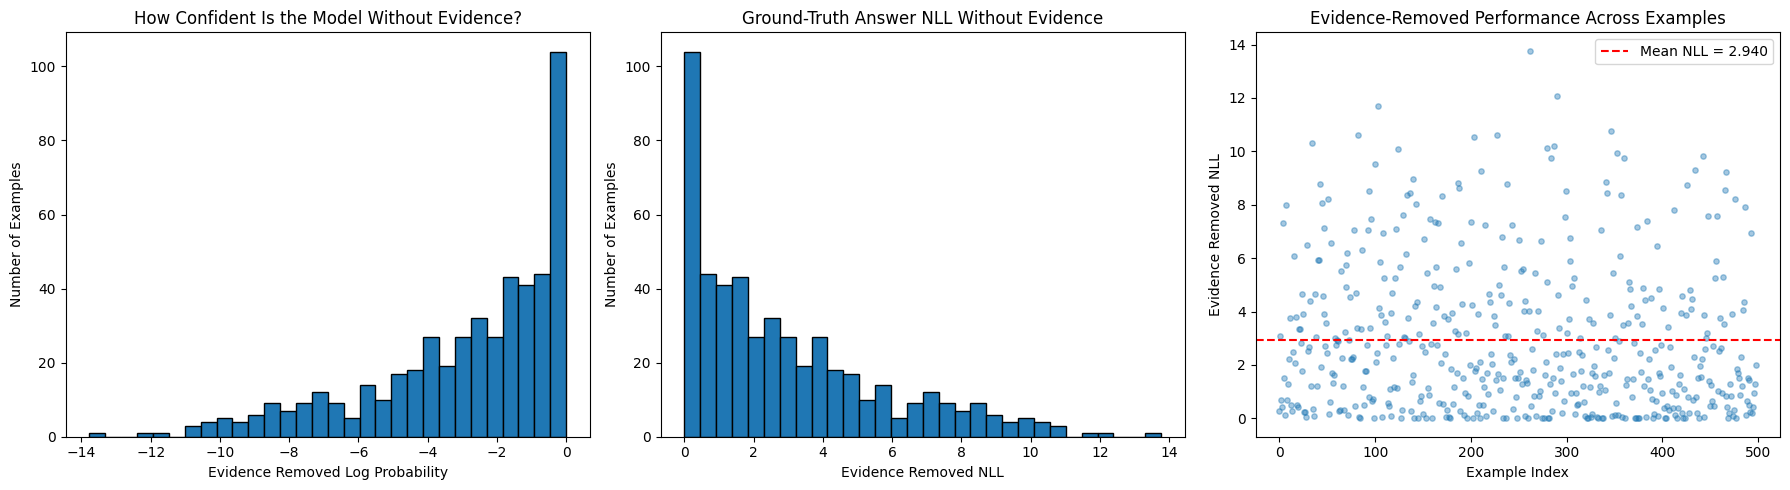

Examples: 499
Mean evidence-removed NLL: 2.940


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

removed = df["evidence_removed_logprob"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Distribution of evidence-removed log probabilities
axes[0].hist(removed, bins=30, edgecolor="black")
axes[0].set_xlabel("Evidence Removed Log Probability")
axes[0].set_ylabel("Number of Examples")
axes[0].set_title("How Confident Is the Model Without Evidence?")

# Plot 2: Distribution of evidence-removed NLL
axes[1].hist(-removed, bins=30, edgecolor="black")
axes[1].set_xlabel("Evidence Removed NLL")
axes[1].set_ylabel("Number of Examples")
axes[1].set_title("Ground-Truth Answer NLL Without Evidence")

# Plot 3: Evidence-removed NLL by example
axes[2].scatter(
    range(len(removed)), -removed,
    alpha=0.4, s=15
)
axes[2].axhline(
    -removed.mean(), color="red", linestyle="--",
    label=f"Mean NLL = {-removed.mean():.3f}"
)
axes[2].set_xlabel("Example Index")
axes[2].set_ylabel("Evidence Removed NLL")
axes[2].set_title("Evidence-Removed Performance Across Examples")
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"Examples: {len(removed)}")
print(f"Mean evidence-removed NLL: {-removed.mean():.3f}")


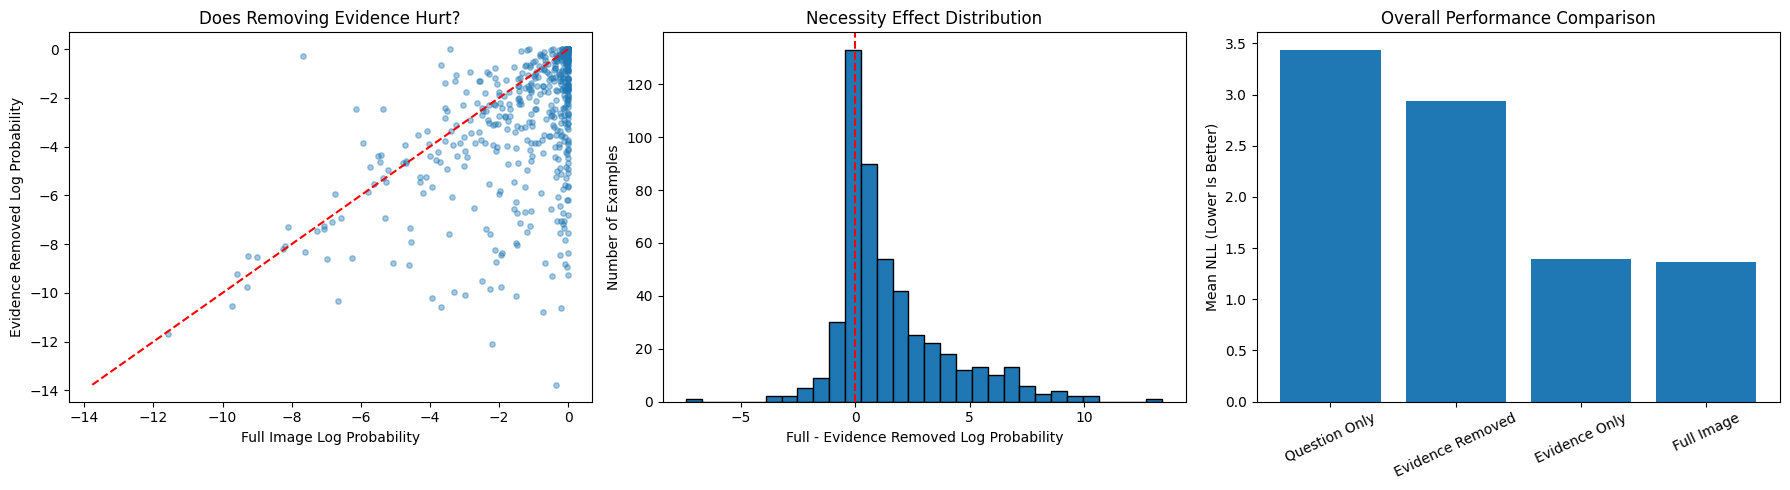

Examples compared: 499
Mean full-image NLL: 1.363
Mean evidence-removed NLL: 2.940
Mean necessity effect: 1.577
Evidence removal hurts in 78.8% of examples


In [ ]:

# Comparing evidence with full evidence

valid_examples = []

for ex in subset:
    if ex["image"] not in skipped:
        valid_examples.append(ex)

aryan_df = pd.DataFrame({
    "image": [ex["image"] for ex in valid_examples],
    "question": [ex["question"] for ex in valid_examples],
    "answer": [ex["answer"].strip().lower() for ex in valid_examples],
    "full_logprob": full_results,
    "evidence_only_logprob": evidence_only_results,
    "qonly_logprob": qonly_results
})

comparison = aryan_df.merge(
    df,
    on=["image", "question", "answer"],
    how="inner",
    validate="one_to_one"
)

full = comparison["full_logprob"].to_numpy()
removed = comparison["evidence_removed_logprob"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Full vs evidence removed
axes[0].scatter(full, removed, alpha=0.4, s=15)
lo = min(full.min(), removed.min())
hi = max(full.max(), removed.max())
axes[0].plot([lo, hi], [lo, hi], "r--")
axes[0].set_xlabel("Full Image Log Probability")
axes[0].set_ylabel("Evidence Removed Log Probability")
axes[0].set_title("Does Removing Evidence Hurt?")

# Plot 2: Distribution of effect
difference = full - removed

axes[1].hist(difference, bins=30, edgecolor="black")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Full - Evidence Removed Log Probability")
axes[1].set_ylabel("Number of Examples")
axes[1].set_title("Necessity Effect Distribution")

# Plot 3: Mean NLL across conditions
conditions = [
    "Question Only", "Evidence Removed",
    "Evidence Only", "Full Image"
]
means = [
    -comparison["qonly_logprob"].mean(),
    -comparison["evidence_removed_logprob"].mean(),
    -comparison["evidence_only_logprob"].mean(),
    -comparison["full_logprob"].mean()
]

axes[2].bar(conditions, means)
axes[2].set_ylabel("Mean NLL (Lower Is Better)")
axes[2].set_title("Overall Performance Comparison")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

print(f"Examples compared: {len(comparison)}")
print(f"Mean full-image NLL: {-full.mean():.3f}")
print(f"Mean evidence-removed NLL: {-removed.mean():.3f}")
print(f"Mean necessity effect: {difference.mean():.3f}")
print(f"Evidence removal hurts in {(difference > 0).mean():.1%} of examples")


In [ ]:
import pandas as pd
from tqdm.auto import tqdm
from PIL import Image, UnidentifiedImageError

irrelevant_region_removed_results = []
errored_images, skipped_irrelevant_region = [], []

for example in tqdm(subset):
    try:
        img = Image.open(
            f"data/image_subset/{example['image']}"
        ).convert("RGB")
    except (UnidentifiedImageError, OSError):
        errored_images.append(example["image"])
        continue

    box = tuple(example["bboxs"][0])
    irrelevant_removed, _ = mask_irrelevant_region(img, box)
    if irrelevant_removed is None:
        skipped_irrelevant_region.append(example["image"])
        continue
    gt = example["answer"].strip().lower()

    total_lp, mean_lp = answer_logprob(
        model, processor, irrelevant_removed,
        example["question"], gt
    )

    irrelevant_region_removed_results.append({
        "image": example["image"],
        "question": example["question"],
        "answer": gt,
        "irrelevant_removed_logprob": mean_lp,
        "irrelevant_removed_logprob_sum": total_lp
    })

    # Same printing style as Aryan
    print(
        f"{example['question'][:45]:45s} "
        f"gt={gt:12s} "
        f"irrelevant_removed={mean_lp:6.2f}"
    )

irrelevant_region_removed_df = pd.DataFrame(irrelevant_region_removed_results)

print("\nSuccessfully evaluated:", len(irrelevant_region_removed_df))
print("No found non-overlapping region images:", skipped_irrelevant_region)
print("Other errored images", errored_images)
print("Mean irrelevant-region-removed NLL:",
      -irrelevant_region_removed_df["irrelevant_removed_logprob"].mean())

irrelevant_region_removed_df.to_csv("results/irrelevant_region_removed_results.csv", index=False)

  0%|          | 0/500 [00:00<?, ?it/s]

Who is wearing a sweater?                     gt=woman        irrelevant_removed= -0.85
What is the towel on?                         gt=bench        irrelevant_removed= -3.15
Which kind of animal is fluffy?               gt=cat          irrelevant_removed= -0.00
What is the man wearing?                      gt=wetsuit      irrelevant_removed= -0.02
Who is wearing a flip flop?                   gt=boy          irrelevant_removed= -8.60
Where is that grass?                          gt=field        irrelevant_removed= -0.71
What is on the table?                         gt=vases        irrelevant_removed= -0.23
What is the binder on?                        gt=shelf        irrelevant_removed= -1.53
What is that water in front of?               gt=trees        irrelevant_removed= -1.46
What kind of watercraft are the passengers on gt=canoe        irrelevant_removed= -2.57
Who is wearing the helmet?                    gt=jockey       irrelevant_removed= -0.03
What item of furniture is broken

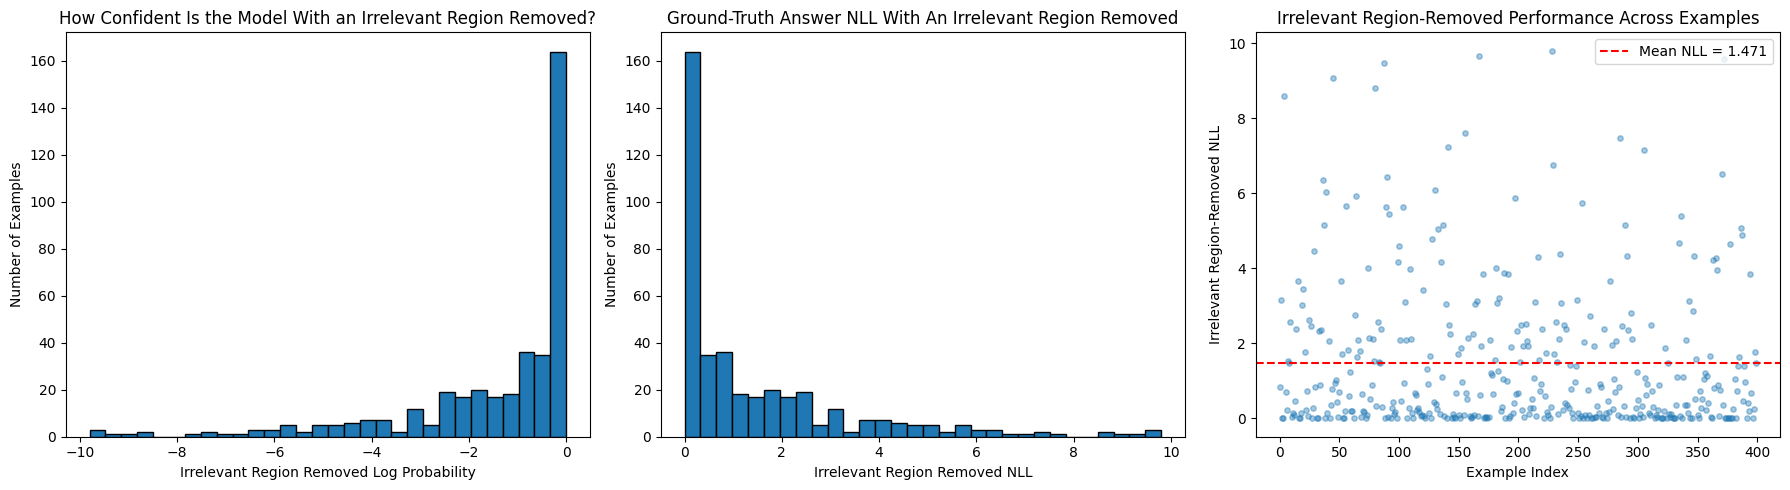

Examples: 400
Mean Irrelevant Region-removed NLL: 1.471


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

irrelevant_region_removed = irrelevant_region_removed_df["irrelevant_removed_logprob"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Distribution of irrelevant-region-removed log probabilities
axes[0].hist(irrelevant_region_removed, bins=30, edgecolor="black")
axes[0].set_xlabel("Irrelevant Region Removed Log Probability")
axes[0].set_ylabel("Number of Examples")
axes[0].set_title("How Confident Is the Model With an Irrelevant Region Removed?")

# Plot 2: Distribution of irrelevant-region-removed NLL
axes[1].hist(-irrelevant_region_removed, bins=30, edgecolor="black")
axes[1].set_xlabel("Irrelevant Region Removed NLL")
axes[1].set_ylabel("Number of Examples")
axes[1].set_title("Ground-Truth Answer NLL With An Irrelevant Region Removed")

# Plot 3: Irrelevant-region-removed NLL by example
axes[2].scatter(
    range(len(irrelevant_region_removed)), -irrelevant_region_removed,
    alpha=0.4, s=15
)
axes[2].axhline(
    -irrelevant_region_removed.mean(), color="red", linestyle="--",
    label=f"Mean NLL = {-irrelevant_region_removed.mean():.3f}"
)
axes[2].set_xlabel("Example Index")
axes[2].set_ylabel("Irrelevant Region-Removed NLL")
axes[2].set_title("Irrelevant Region-Removed Performance Across Examples")
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"Examples: {len(irrelevant_region_removed)}")
print(f"Mean Irrelevant Region-removed NLL: {-irrelevant_region_removed.mean():.3f}")


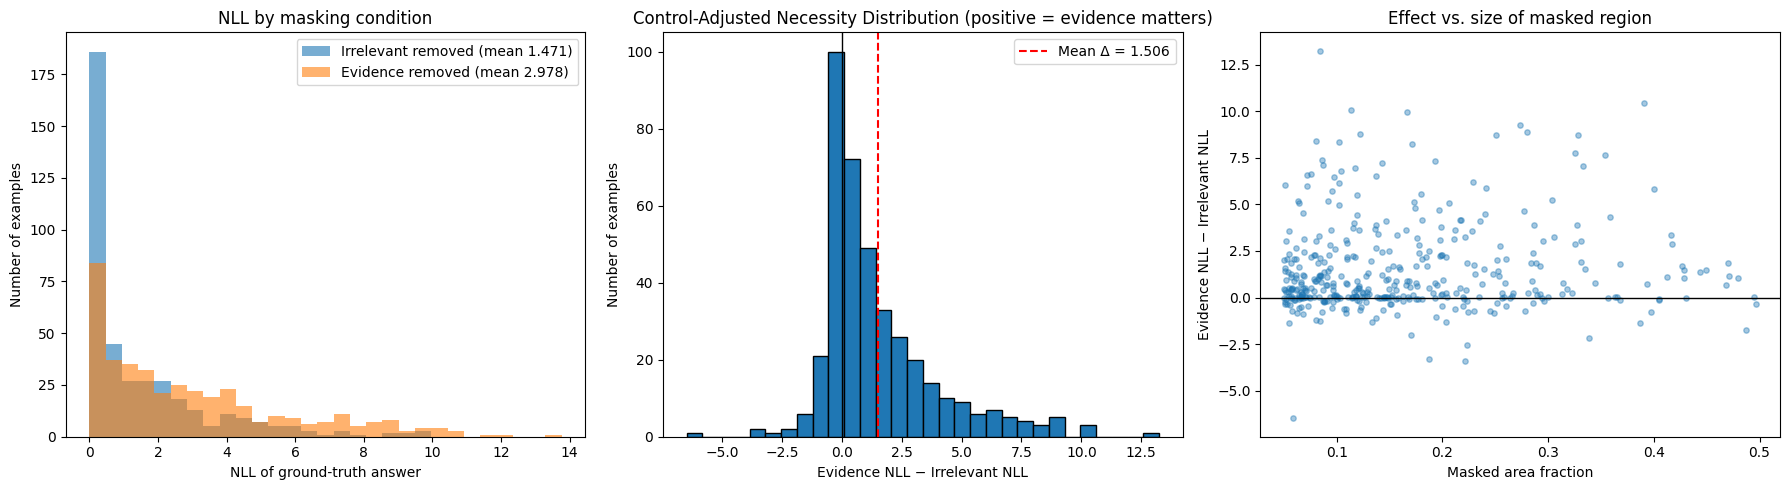

Paired examples:               400
Mean irrelevant-removed NLL:   1.471
Mean evidence-removed NLL:     2.978
Control-Adjusted Necessity (evidence − irrelevant): 1.506  (95% bootstrap CI [1.272, 1.744])
Median Necessity:                      0.692
Fraction where evidence hurts more: 77.75%
Wilcoxon signed-rank p-value:  9.65e-35


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

# --- config: adjust to your variable/column names ---
EVI_DF  = pd.read_csv("results/evidence_removed_results.csv")
EVI_COL = "evidence_removed_logprob"
IRR_DF  = irrelevant_region_removed_df
IRR_COL = "irrelevant_removed_logprob"
keys = ["image", "question"]

# area fraction of the evidence box, computed from the source records
area_rows = []
for ex in subset:
    W, H = ex["width"], ex["height"]
    x1, y1, x2, y2 = ex["bboxs"][0]
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
    area_rows.append({
        "image": ex["image"], "question": ex["question"],
        "area_frac": (x2 - x1) * (y2 - y1) / (W * H),
    })
area_df = pd.DataFrame(area_rows).drop_duplicates(keys)

# inner join keeps only examples that survived in BOTH conditions
merged = (
    IRR_DF[keys + [IRR_COL]]
    .merge(EVI_DF[keys + [EVI_COL]], on=keys, how="inner")
    .merge(area_df, on=keys, how="left")
)

irr_nll = -merged[IRR_COL].to_numpy()
evi_nll = -merged[EVI_COL].to_numpy()
delta = evi_nll - irr_nll  # > 0: hiding the evidence hurts more than hiding a random region

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1: NLL distributions by condition
bins = np.linspace(min(irr_nll.min(), evi_nll.min()),
                   max(irr_nll.max(), evi_nll.max()), 30)
axes[0].hist(irr_nll, bins=bins, alpha=0.6, label=f"Irrelevant removed (mean {irr_nll.mean():.3f})")
axes[0].hist(evi_nll, bins=bins, alpha=0.6, label=f"Evidence removed (mean {evi_nll.mean():.3f})")
axes[0].set_xlabel("NLL of ground-truth answer")
axes[0].set_ylabel("Number of examples")
axes[0].set_title("NLL by masking condition")
axes[0].legend()

# 2: paired per-example difference
axes[1].hist(delta, bins=30, edgecolor="black")
axes[1].axvline(0, color="black", linewidth=1)
axes[1].axvline(delta.mean(), color="red", linestyle="--",
                label=f"Mean Δ = {delta.mean():.3f}")
axes[1].set_xlabel("Evidence NLL − Irrelevant NLL")
axes[1].set_ylabel("Number of examples")
axes[1].set_title("Control-Adjusted Necessity Distribution (positive = evidence matters)")
axes[1].legend()

# 3: does the effect depend on how much was masked?
axes[2].scatter(merged["area_frac"], delta, alpha=0.4, s=15)
axes[2].axhline(0, color="black", linewidth=1)
axes[2].set_xlabel("Masked area fraction")
axes[2].set_ylabel("Evidence NLL − Irrelevant NLL")
axes[2].set_title("Effect vs. size of masked region")

plt.tight_layout()
plt.show()

# --- summary stats ---
rng_boot = np.random.default_rng(0)
boot = [rng_boot.choice(delta, len(delta)).mean() for _ in range(5000)]
lo, hi = np.percentile(boot, [2.5, 97.5])
stat, p = wilcoxon(delta)

print(f"Paired examples:               {len(merged)}")
print(f"Mean irrelevant-removed NLL:   {irr_nll.mean():.3f}")
print(f"Mean evidence-removed NLL:     {evi_nll.mean():.3f}")
print(f"Control-Adjusted Necessity (evidence − irrelevant): {delta.mean():.3f}  (95% bootstrap CI [{lo:.3f}, {hi:.3f}])")
print(f"Median Necessity:                      {np.median(delta):.3f}")
print(f"Fraction where evidence hurts more: {(delta > 0).mean():.2%}")
print(f"Wilcoxon signed-rank p-value:  {p:.3g}")